# Supermarket Sales Analysis

## Project Overview

This project explores supermarket sales data to identify sales trends, evaluate product category performance, and understand how different outlet characteristics influence overall sales.

## Objectives

- Analyse overall sales performance.
- Identify the highest and lowest performing product categories.
- Compare sales across outlet types, sizes and locations.
- Examine the relationship between product visibility and sales.
- Generate insights and recommendations to support business decisions.

## Tools and Technologies

Python, Pandas, NumPy and Matplotlib.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import micropip
await micropip.install("openpyxl")

In [5]:
df = pd.read_excel("Supermarket Sales Analysis Dashboard (V.2).xlsx")

df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (8523, 12)

Column Names:
Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility    

In [7]:
print(df.isnull().sum())

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


In [8]:
# Fill missing weights using the median weight of each item
df['Item Weight'] = df.groupby('Item Identifier')['Item Weight'].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining missing values using the overall median
df['Item Weight'] = df['Item Weight'].fillna(df['Item Weight'].median())

# Check missing values again
print(df.isnull().sum())

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
categorical_columns = [
    'Item Fat Content',
    'Item Type',
    'Outlet Location Type',
    'Outlet Size',
    'Outlet Type'
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 Item Fat Content
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

 Item Type
Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

 Outlet Location Type
Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

 Outlet Size
Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64

 Outlet Type
Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Ty

In [11]:
# Standardise Item Fat Content labels

df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

# Check the corrected categories
print(df['Item Fat Content'].value_counts())

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


In [12]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,12.875314,140.992783,3.965857
std,3.189396,0.051598,4.645010,62.275067,0.605651
min,2011.000000,0.000000,4.555000,31.290000,1.000000
25%,2014.000000,0.026989,8.785000,93.826500,4.000000
50%,2016.000000,0.053931,12.650000,143.012800,4.000000
75%,2018.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [13]:
print("Total Sales:", df['Sales'].sum())
print("Average Sales:", df['Sales'].mean())
print("Highest Sale:", df['Sales'].max())
print("Lowest Sale:", df['Sales'].min())

Total Sales: 1201681.4928000001
Average Sales: 140.99278338613166
Highest Sale: 266.8884
Lowest Sale: 31.29


In [14]:
sales_by_item = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_item)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


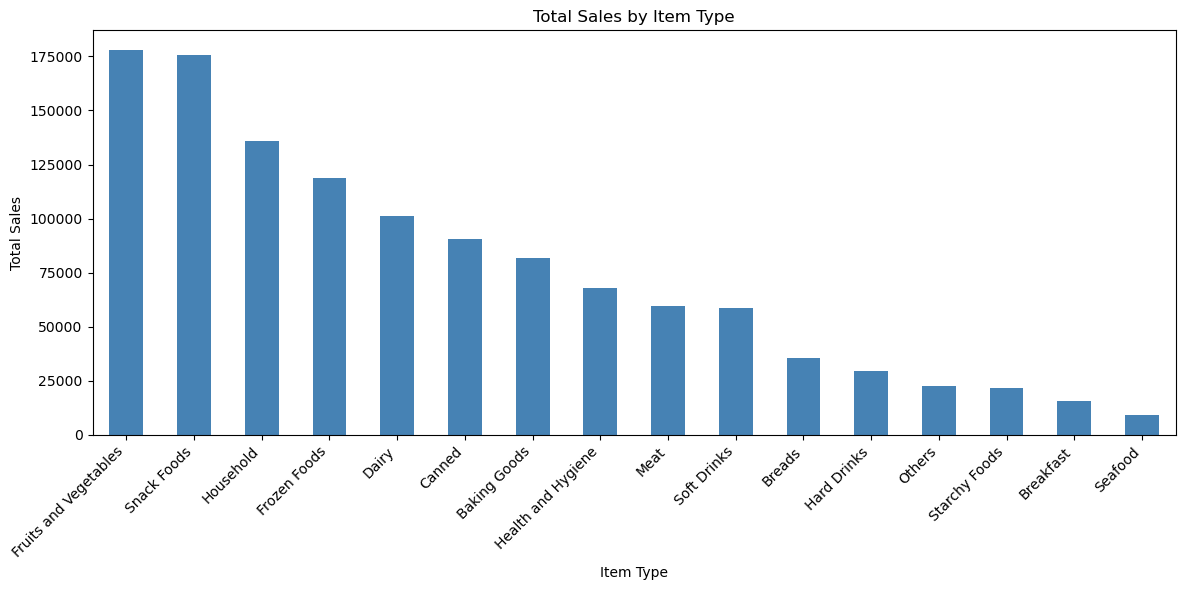

In [15]:
plt.figure(figsize=(12, 6))

sales_by_item.plot(kind='bar', color='steelblue')

plt.title('Total Sales by Item Type')
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [16]:
sales_by_outlet = df.groupby('Outlet Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_outlet)

Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


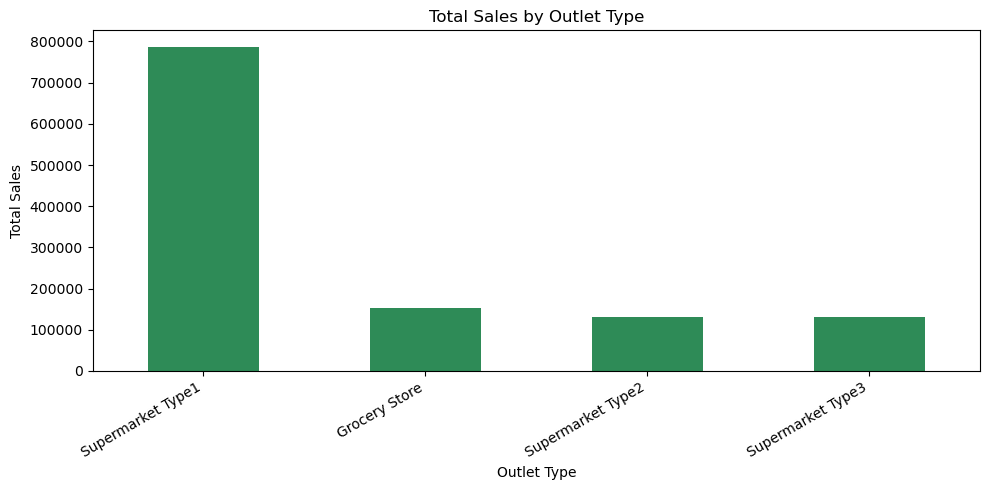

In [17]:
plt.figure(figsize=(10, 5))

sales_by_outlet.plot(kind='bar', color='seagreen')

plt.title('Total Sales by Outlet Type')
plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [18]:
outlet_analysis = df.groupby('Outlet Type').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count'),
    Number_of_Outlets=('Outlet Identifier', 'nunique')
)

print(outlet_analysis.sort_values('Total_Sales', ascending=False))

                   Total_Sales  Average_Sales  Number_of_Records  \
Outlet Type                                                        
Supermarket Type1  787549.8928     141.213895               5577   
Grocery Store      151939.1490     140.294690               1083   
Supermarket Type2  131477.7764     141.678638                928   
Supermarket Type3  130714.6746     139.801791                935   

                   Number_of_Outlets  
Outlet Type                           
Supermarket Type1                  6  
Grocery Store                      2  
Supermarket Type2                  1  
Supermarket Type3                  1  


In [19]:
location_sales = df.groupby('Outlet Location Type').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count'),
    Number_of_Outlets=('Outlet Identifier', 'nunique')
)

print(location_sales.sort_values('Total_Sales', ascending=False))

                      Total_Sales  Average_Sales  Number_of_Records  \
Outlet Location Type                                                  
Tier 3                472133.0332     140.935234               3350   
Tier 2                393150.6476     141.167198               2785   
Tier 1                336397.8120     140.870106               2388   

                      Number_of_Outlets  
Outlet Location Type                     
Tier 3                                4  
Tier 2                                3  
Tier 1                                3  


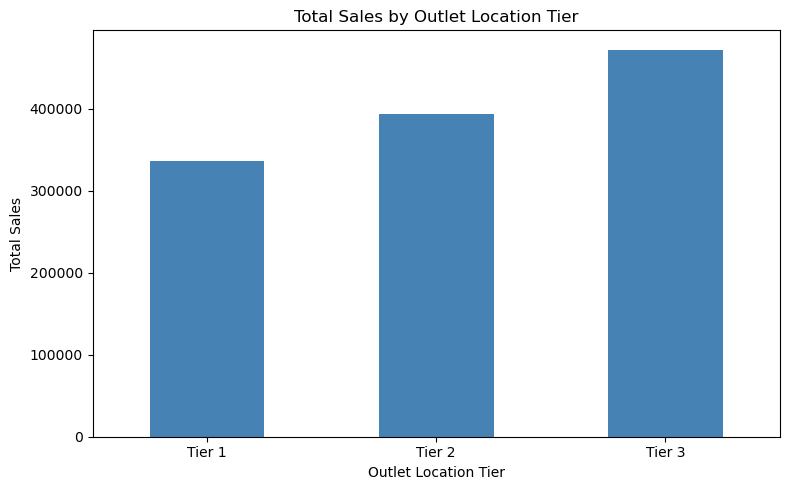

In [20]:
plt.figure(figsize=(8, 5))

location_sales['Total_Sales'].sort_values().plot(
    kind='bar',
    color='steelblue'
)

plt.title('Total Sales by Outlet Location Tier')
plt.xlabel('Outlet Location Tier')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [21]:
size_sales = df.groupby('Outlet Size').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count'),
    Number_of_Outlets=('Outlet Identifier', 'nunique')
)

print(size_sales.sort_values('Total_Sales', ascending=False))

             Total_Sales  Average_Sales  Number_of_Records  Number_of_Outlets
Outlet Size                                                                  
Medium       507895.7364     139.877647               3631                  6
Small        444794.1704     141.699322               3139                  6
High         248991.5860     142.037414               1753                  4


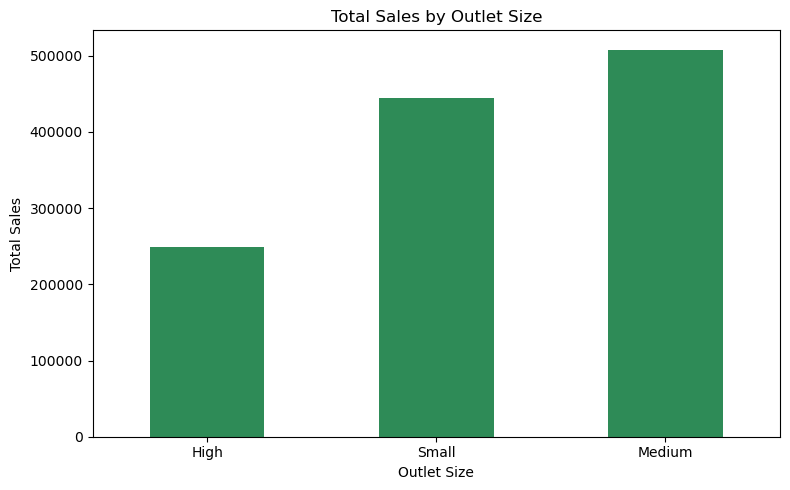

In [22]:
plt.figure(figsize=(8, 5))

size_sales['Total_Sales'].sort_values().plot(
    kind='bar',
    color='seagreen'
)

plt.title('Total Sales by Outlet Size')
plt.xlabel('Outlet Size')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [23]:
fat_sales = df.groupby('Item Fat Content').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count')
)

print(fat_sales.sort_values('Total_Sales', ascending=False))

                  Total_Sales  Average_Sales  Number_of_Records
Item Fat Content                                               
Low Fat           776319.6884      140.71410               5517
Regular           425361.8044      141.50426               3006


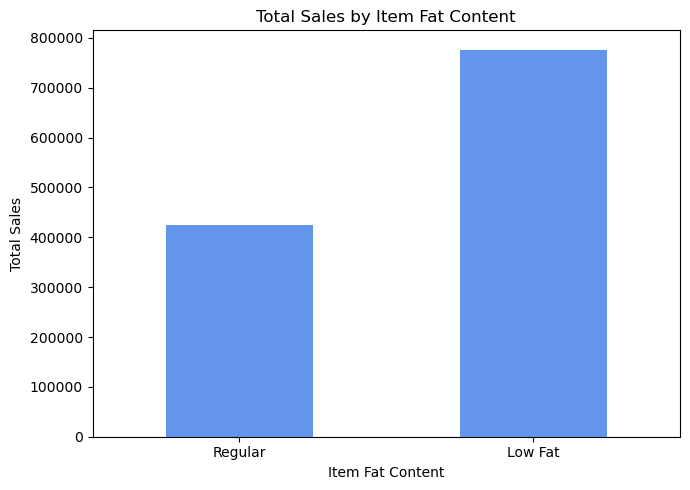

In [24]:
plt.figure(figsize=(7, 5))

fat_sales['Total_Sales'].sort_values().plot(
    kind='bar',
    color='cornflowerblue'
)

plt.title('Total Sales by Item Fat Content')
plt.xlabel('Item Fat Content')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [26]:
item_sales = df.groupby('Item Type').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count')
)

print(item_sales.sort_values('Total_Sales', ascending=False))

                       Total_Sales  Average_Sales  Number_of_Records
Item Type                                                           
Fruits and Vegetables  178124.0810     144.581235               1232
Snack Foods            175433.9224     146.194935               1200
Household              135976.5254     149.424753                910
Frozen Foods           118558.8814     138.503366                856
Dairy                  101276.4616     148.499211                682
Canned                  90706.7290     139.763835                649
Baking Goods            81894.7364     126.380766                648
Health and Hygiene      68025.8388     130.818921                520
Meat                    59449.8638     139.882032                425
Soft Drinks             58514.1670     131.492510                445
Breads                  35379.1198     140.952669                251
Hard Drinks             29334.6806     137.077947                214
Others                  22451.8916

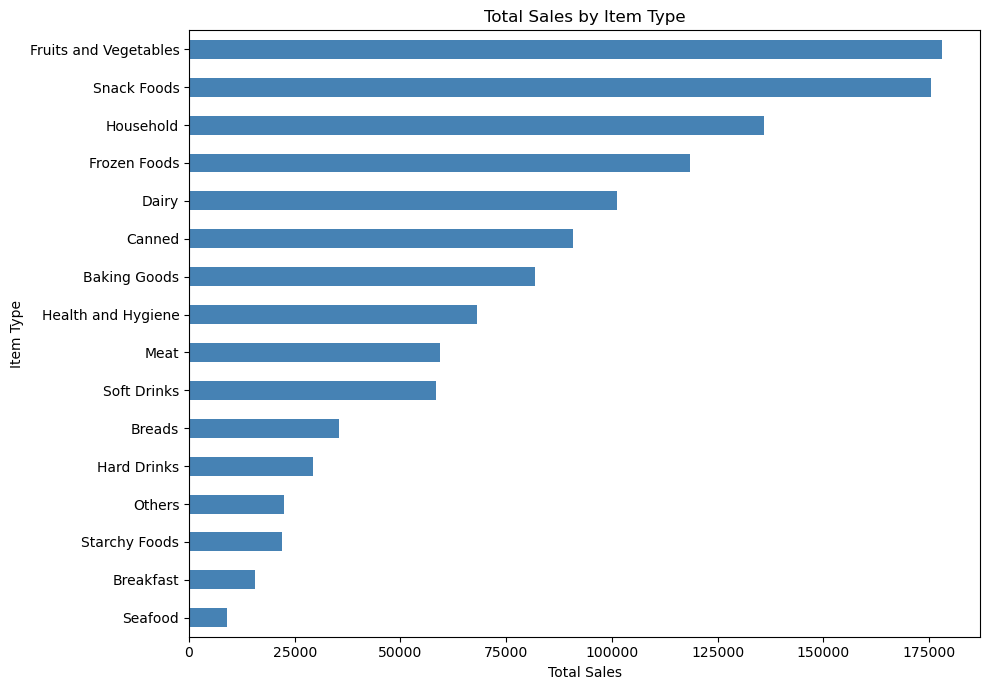

In [27]:
plt.figure(figsize=(10, 7))

item_sales['Total_Sales'].sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Total Sales by Item Type')
plt.xlabel('Total Sales')
plt.ylabel('Item Type')

plt.tight_layout()
plt.show()

In [28]:
year_sales = df.groupby('Outlet Establishment Year').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count'),
    Number_of_Outlets=('Outlet Identifier', 'nunique')
)

print(year_sales.sort_values('Outlet Establishment Year'))

                           Total_Sales  Average_Sales  Number_of_Records  \
Outlet Establishment Year                                                  
2011                        78131.5666     140.777597                555   
2012                       130476.8598     140.297699                930   
2014                       131809.0156     141.425982                932   
2015                       130942.7802     140.950248                929   
2016                       132113.3698     142.057387                930   
2017                       133103.9070     143.122481                930   
2018                       204522.2570     139.796485               1463   
2020                       129103.9604     139.421124                926   
2022                       131477.7764     141.678638                928   

                           Number_of_Outlets  
Outlet Establishment Year                     
2011                                       1  
2012                  

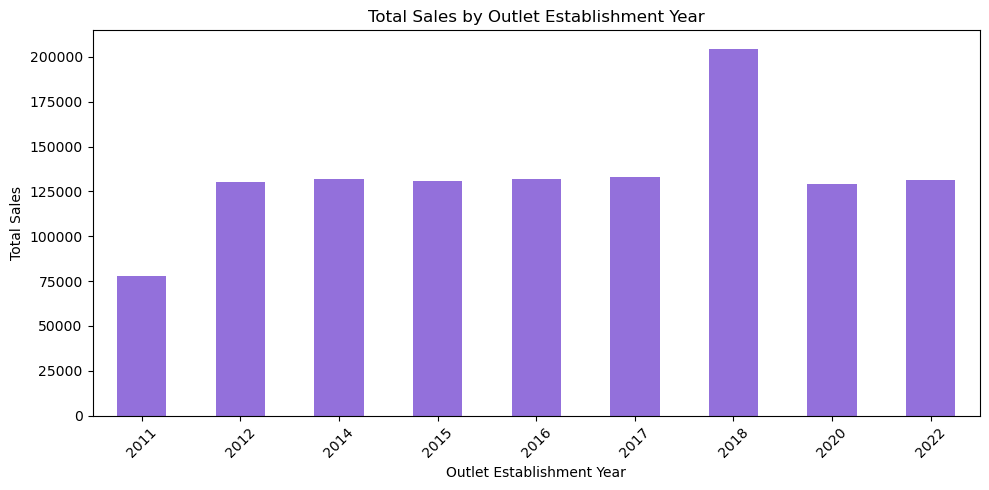

In [31]:
plt.figure(figsize=(10, 5))

year_sales['Total_Sales'].plot(
    kind='bar',
    color='mediumpurple'
)

plt.title('Total Sales by Outlet Establishment Year')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [32]:

# Top 4 Item Types by Total Sales

sales_by_item = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

top_4_sales = sales_by_item.head(4).sum()
remaining_sales = sales_by_item.iloc[4:].sum()
total_sales = df['Sales'].sum()

top_4_percentage = (top_4_sales / total_sales) * 100
remaining_percentage = (remaining_sales / total_sales) * 100

print("Top 4 Item Types Sales:", round(top_4_sales, 2))
print("Remaining Item Types Sales:", round(remaining_sales, 2))
print("Top 4 Contribution:", round(top_4_percentage, 2), "%")
print("Remaining Contribution:", round(remaining_percentage, 2), "%")


Top 4 Item Types Sales: 608093.41
Remaining Item Types Sales: 593588.08
Top 4 Contribution: 50.6 %
Remaining Contribution: 49.4 %


In [33]:

# Identify highest and lowest sales-performing Item Types

print("Highest Sales Item Type:")
print(sales_by_item.idxmax(), "-", round(sales_by_item.max(), 2))

print("\nLowest Sales Item Type:")
print(sales_by_item.idxmin(), "-", round(sales_by_item.min(), 2))


Highest Sales Item Type:
Fruits and Vegetables - 178124.08

Lowest Sales Item Type:
Seafood - 9077.87


In [34]:

# Sales comparison by Outlet Type and Item Fat Content

fat_outlet_sales = df.pivot_table(
    index='Outlet Type',
    columns='Item Fat Content',
    values='Sales',
    aggfunc='sum'
)

print(fat_outlet_sales.round(2))


Item Fat Content     Low Fat    Regular
Outlet Type                            
Grocery Store       99814.37   52124.78
Supermarket Type1  507886.30  279663.59
Supermarket Type2   84844.61   46633.17
Supermarket Type3   83774.41   46940.26


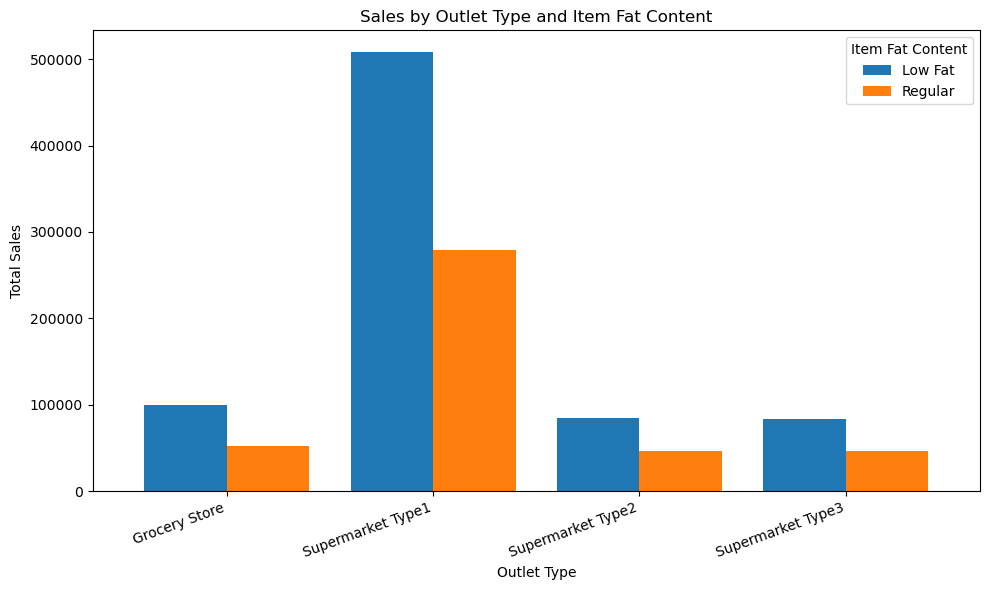

In [35]:

# Visualise Low Fat vs Regular sales by Outlet Type

fat_outlet_sales.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8
)

plt.title('Sales by Outlet Type and Item Fat Content')
plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Item Fat Content')
plt.tight_layout()
plt.show()


In [37]:

# Calculate correlation between Item Visibility and Sales

correlation = df['Item Visibility'].corr(df['Sales'])

print("Correlation between Item Visibility and Sales:", round(correlation, 4))


Correlation between Item Visibility and Sales: -0.0013


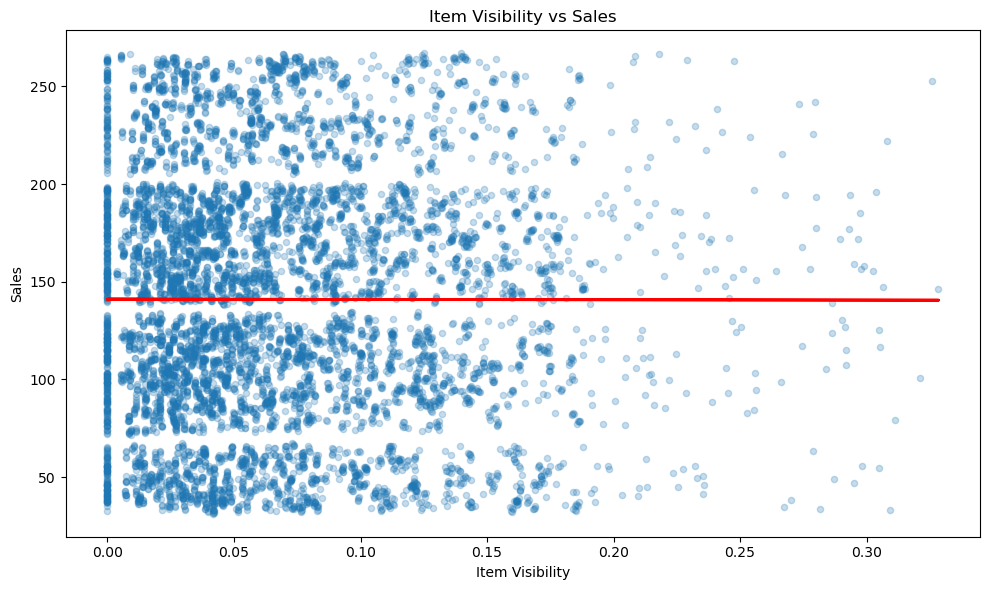

In [43]:

# Item Visibility vs Sales with trendline

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Item Visibility'],
    df['Sales'],
    alpha=0.25,
    s=20
)

# Add a linear trendline
m, b = np.polyfit(
    df['Item Visibility'],
    df['Sales'],
    1
)

plt.plot(
    df['Item Visibility'],
    m * df['Item Visibility'] + b,
    color='red',
    linewidth=2
)

plt.title('Item Visibility vs Sales')
plt.xlabel('Item Visibility')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()


In [44]:

# Item Type sales across different Outlet Types

category_outlet_sales = df.pivot_table(
    index='Item Type',
    columns='Outlet Type',
    values='Sales',
    aggfunc='sum'
)

print(category_outlet_sales.round(2))


Outlet Type            Grocery Store  Supermarket Type1  Supermarket Type2  \
Item Type                                                                    
Baking Goods                10747.24           53665.46            8594.20   
Breads                       4832.94           22490.81            3539.40   
Breakfast                    2793.51            9632.65            1552.61   
Canned                      10079.90           59649.31           10852.47   
Dairy                       13539.34           67179.69           10638.94   
Frozen Foods                13750.44           79348.38           13253.72   
Fruits and Vegetables       21423.41          117431.99           18967.29   
Hard Drinks                  2812.54           19610.76            3609.12   
Health and Hygiene           8964.02           44050.75            7339.92   
Household                   18082.11           89143.41           14244.65   
Meat                         9081.05           36169.76         

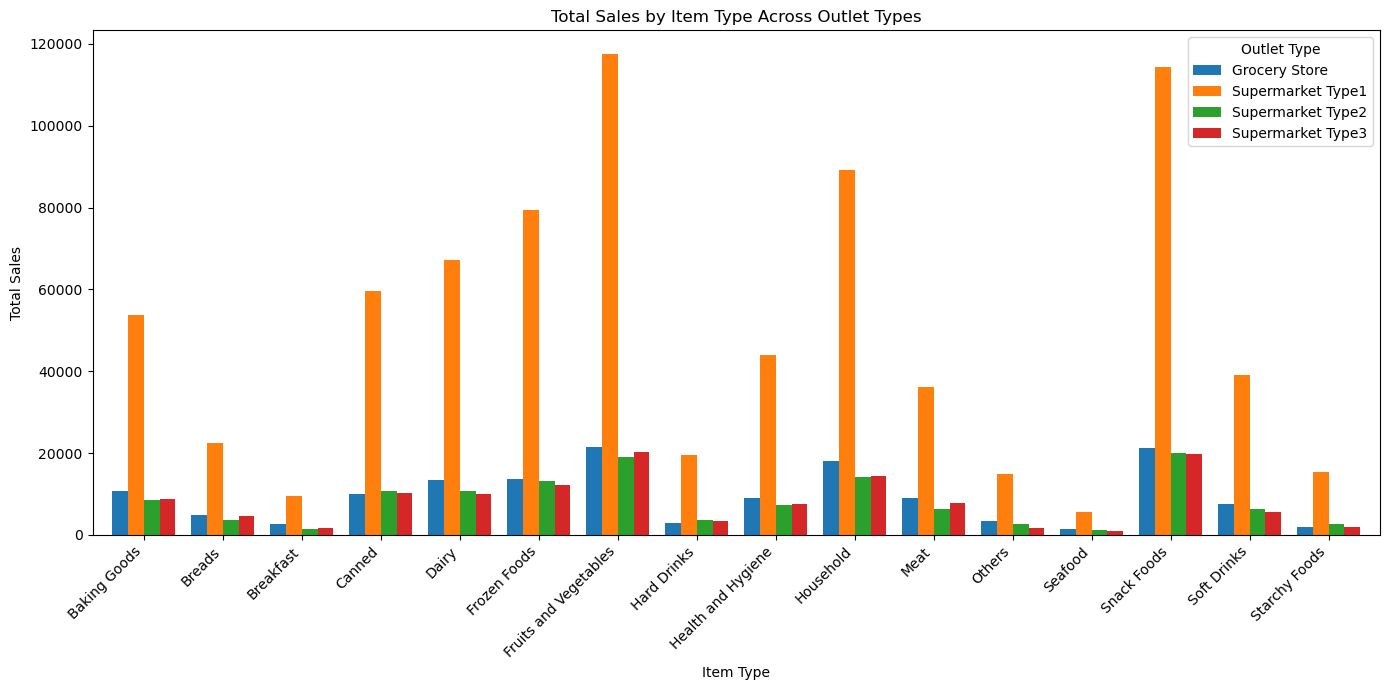

In [46]:

# Grouped Bar Chart: Item Type Sales Across Outlet Types

category_outlet_sales.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Total Sales by Item Type Across Outlet Types')
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Outlet Type')
plt.tight_layout()
plt.show()


In [47]:

# Sales variation: Standard Deviation and Variance

print("Standard Deviation:", round(df['Sales'].std(), 2))
print("Variance:", round(df['Sales'].var(), 2))


Standard Deviation: 62.28
Variance: 3878.18


In [48]:

# Detect outliers using the IQR method

Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Sales'] < lower_limit) |
    (df['Sales'] > upper_limit)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Limit:", round(lower_limit, 2))
print("Upper Limit:", round(upper_limit, 2))
print("Number of Outliers:", len(outliers))


Q1: 93.83
Q3: 185.64
IQR: 91.82
Lower Limit: -43.9
Upper Limit: 323.37
Number of Outliers: 0


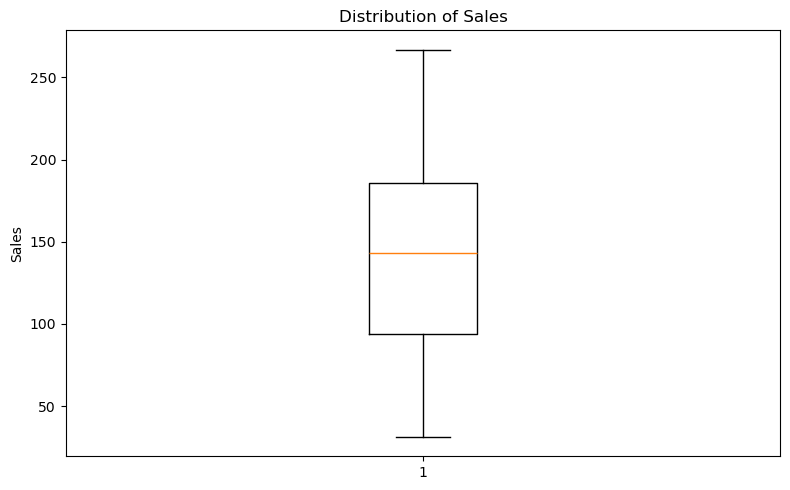

In [49]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['Sales'], vert=True)

plt.title('Distribution of Sales')
plt.ylabel('Sales')

plt.tight_layout()
plt.show()

In [50]:
print("Average Product Visibility:",
      round(df['Item Visibility'].mean(), 4))

Average Product Visibility: 0.0661


In [51]:
# Average sales by product category
avg_sales_category = df.groupby('Item Type')['Sales'].mean().sort_values(ascending=False)

print("Average Sales by Product Category:")
print(avg_sales_category.round(2))

Average Sales by Product Category:
Item Type
Household                149.42
Dairy                    148.50
Starchy Foods            147.84
Snack Foods              146.19
Fruits and Vegetables    144.58
Seafood                  141.84
Breakfast                141.79
Breads                   140.95
Meat                     139.88
Canned                   139.76
Frozen Foods             138.50
Hard Drinks              137.08
Others                   132.85
Soft Drinks              131.49
Health and Hygiene       130.82
Baking Goods             126.38
Name: Sales, dtype: float64


In [52]:
avg_sales_outlet = df.groupby('Outlet Type')['Sales'].mean().sort_values(ascending=False)

print("Average Sales by Outlet Type:")
print(avg_sales_outlet.round(2))

Average Sales by Outlet Type:
Outlet Type
Supermarket Type2    141.68
Supermarket Type1    141.21
Grocery Store        140.29
Supermarket Type3    139.80
Name: Sales, dtype: float64


In [53]:
avg_sales_location = df.groupby('Outlet Location Type')['Sales'].mean().sort_values(ascending=False)

print("Average Sales by Outlet Location:")
print(avg_sales_location.round(2))

Average Sales by Outlet Location:
Outlet Location Type
Tier 2    141.17
Tier 3    140.94
Tier 1    140.87
Name: Sales, dtype: float64


# Key Findings and Business Insights

## 1. Product Category Performance
Fruits and Vegetables generated the highest sales, followed by Snack Foods. Seafood recorded the lowest sales.

## 2. Outlet Performance
Supermarket Type1 contributed the highest total sales among outlet types.

## 3. Outlet Location
Tier 3 outlets recorded the highest total sales among the three location tiers.

## 4. Product Fat Content
Low Fat products generated higher total sales than Regular products.

## 5. Item Visibility
The correlation between Item Visibility and Sales was -0.0013, indicating virtually no linear relationship between the two variables.

## 6. Sales Contribution
The top four item types accounted for approximately 50.6% of total sales.

# Conclusion and Recommendations

The analysis shows that sales performance varies across product categories and outlet characteristics. Fruits and Vegetables and Snack Foods are major contributors to overall sales, while Seafood has the lowest sales contribution.

Based on these findings, the business could:

- Maintain adequate inventory for high-performing product categories.
- Review the sales performance of lower-performing categories.
- Evaluate outlet-level strategies to improve sales.
- Explore other factors influencing product sales, as item visibility alone does not explain sales variation.

Overall, this analysis provides insights into supermarket sales patterns and can support more informed inventory and business planning decisions.